# M1-INF4 — Python Workshop for Data Analysis
## Session 5 — Data Integration Case Study

### A retail decision supported by reliable data
You are a small analytics team working for **Campus Tech**, a fictional retailer of computer accessories and equipment. The manager wants to compare stores before deciding where to investigate further.

> “The store with the highest total sales is our best-performing store. We should copy its approach everywhere.”

**Your mission:** integrate three sources, assess this claim and deliver an evidence-based recommendation.

This is a synthesis project. Use the pandas and Matplotlib techniques from Sessions 1–4. No new library or advanced modelling is required.

**All data are synthetic. Some records deliberately contain quality issues for training.** Findings describe this supplied sample, not a real company.

### What the data represent
The intended scope is **1–28 April 2025 inclusive**. This is an extract of completed orders, **not a complete record of all activity**. Coverage can differ between stores. A day absent from the extract is not evidence of zero sales or store closure.

| File | One row represents | Expected key | Purpose |
|---|---|---|---|
| `case_sales.csv` | One completed order for one product, possibly several units | `order_id` | Recorded quantity and unit selling price |
| `case_stores.csv` | One store | `store_id` | Store name, city and format |
| `case_products.csv` | One product | `product_id` | Product name and category |

Each order concerns **one product only**, so one valid order row is one order, not a line in a multi-product basket. The price is the final selling price per unit in EUR, after discounts and excluding VAT. Returns and cancellations are outside this extract.

Revenue per order = quantity × unit selling price. **Revenue is not profit**: costs, staffing, opening hours and customer traffic are unavailable.

The reference files should have unique keys, but this must be checked. Repeated store or product IDs in the sales file are normal.

### Data dictionary
| Field | Meaning and rule |
|---|---|
| `order_id` | Order identifier, required and unique after removing exact repeated records |
| `date` | Order date, expected format `YYYY-MM-DD`, within the study window |
| `store_id`, `product_id` | Reference keys; trim spaces and normalise case before joining |
| `quantity` | Positive whole number of units |
| `unit_price_eur` | Positive numeric unit price; a decimal comma may occur |
| `store_name`, `city`, `store_format` | Store attributes; “Small”/“Large” describes format, not observed floor area |
| `product_name`, `category` | Product attributes |

**Quality policy:** keep raw objects unchanged. Remove exact duplicate rows with an audit count. Convert invalid dates/numbers to missing values. Keep invalid or unmatched records in review tables, without inventing replacements. Do not remove a large but valid order simply because it is unusual. If duplicate reference keys disagree, investigate rather than arbitrarily keeping the first row.

### Files and group deliverable
Place this notebook in `notebooks/` and the three CSV files in the neighbouring `data/` folder. You may also put the CSV files beside the notebook.

Submit one completed notebook per group, the exported summary tables and three labelled figures. Record group members below. Divide the work, then review the entire analysis together: **every member must be able to explain the data unit, cleaning choices, joins and conclusions**.

Group members (G10): Élodie CAO, Steve YEE KON PINE, Daria QUESNEL, Insafe LAHBICHI

The sections below form one continuous analysis. Each checkpoint is a review of your own results, not a separate dataset.

In [21]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path('../data'), Path('data'), Path('.')]
DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in
    ['case_sales.csv', 'case_stores.csv', 'case_products.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError('Place the three case_*.csv files in data/ or beside this notebook.')
OUT_DIR = Path('case_study_outputs')
OUT_DIR.mkdir(exist_ok=True)

sales_raw = pd.read_csv(DATA_DIR / 'case_sales.csv', dtype='string')
stores_raw = pd.read_csv(DATA_DIR / 'case_stores.csv', dtype='string')
products_raw = pd.read_csv(DATA_DIR / 'case_products.csv', dtype='string')
for name, frame in [('Sales', sales_raw), ('Stores', stores_raw), ('Products', products_raw)]:
    print(name, frame.shape)
    display(frame.head())

Sales (252, 6)


,order_id,date,store_id,product_id,quantity,unit_price_eur
0,O0001,2025-04-21,s1,P02,3,19.90
1,O0002,2025-04-14,S1,p02,2,39.90
2,O0003,2025-04-14,S1,P04,1,"179,00"
3,O0004,2025-04-31,S1,P03,1,179.00
4,O0005,2025-04-09,S1,P02,two,19.90


Stores (4, 4)


,store_id,store_name,city,store_format
0,S1,Paris Centre,Paris,Small
1,S2,Paris Est,Paris,Large
2,S3,Lyon Centre,Lyon,Small
3,S4,Lille Centre,Lille,Large


Products (7, 3)


,product_id,product_name,category
0,P01,Keyboard,Accessories
1,P02,Mouse,Accessories
2,P03,Monitor,Screens
3,P04,Headset,Audio
4,P05,Webcam,Video


## 1. Understand and audit the sources
1. Report row and column counts, missing values and exact duplicate counts for each source.
2. Check the expected keys. Explain why repeated `store_id` values are acceptable in sales but potentially dangerous in stores.
3. Write the observation unit and the proposed join keys before joining anything.

**Checkpoint:** your audit should distinguish missing data, repeated records and normal repeated foreign keys.

In [22]:
#1 

print("Nombre de lignes et colonnes de sales : ", sales_raw.shape)
print("Nombre de lignes et colonnes de stores : ", stores_raw.shape)
print("Nombre de lignes et colonnes de products : ", products_raw.shape)

print("Valeurs manquantes de sales : ", sales_raw.isna().sum())
print("Valeurs manquantes de stores : ", stores_raw.isna().sum())
print("Valeurs manquantes de products : ", products_raw.isna().sum()) 

print("Valeurs dupliquées de sales : ", sales_raw.duplicated().sum())
print("Valeurs dupliquées de stores : ", stores_raw.duplicated().sum())
print("Valeurs dupliquées de products : ", products_raw.duplicated().sum())

#2

# Clé attendue de sales : order_id (doit être unique)
print("order_id manquants dans sales : ", sales_raw['order_id'].isna().sum())
print("order_id dupliqués dans sales : ", sales_raw['order_id'].duplicated().sum())
print("order_id dupliqués dans sales après suppression des doublons exacts : ",
      sales_raw.drop_duplicates()['order_id'].duplicated().sum())

# Clé attendue de stores : store_id (doit être unique)
print("store_id manquants dans stores : ", stores_raw['store_id'].isna().sum())
print("store_id dupliqués dans stores : ", stores_raw['store_id'].duplicated().sum())

# Clé attendue de products : product_id (doit être unique)
print("product_id manquants dans products : ", products_raw['product_id'].isna().sum())
print("product_id dupliqués dans products : ", products_raw['product_id'].duplicated().sum())
display(products_raw[products_raw['product_id'].duplicated(keep=False)])

# Dans sales, store_id et product_id sont des clés étrangères : les répétitions sont normales
print("Nombre de commandes par store_id dans sales : ")
print(sales_raw['store_id'].value_counts(dropna=False))
print("Nombre de commandes par product_id dans sales : ")
print(sales_raw['product_id'].value_counts(dropna=False))

# Les identifiants bruts ne sont pas normalisés (espaces, minuscules) : on le vérifie sans modifier sales_raw
print("store_id distincts bruts : ", sales_raw['store_id'].nunique(),
      "/ après normalisation : ", sales_raw['store_id'].str.strip().str.upper().nunique())
print("product_id distincts bruts : ", sales_raw['product_id'].nunique(),
      "/ après normalisation : ", sales_raw['product_id'].str.strip().str.upper().nunique())

#3

print("Unité d'observation de sales : une commande (order_id)")
print("Unité d'observation de stores : un magasin (store_id)")
print("Unité d'observation de products : un produit (product_id)")
print("Jointures prévues : sales.store_id -> stores.store_id et sales.product_id -> products.product_id")


Nombre de lignes et colonnes de sales :  (252, 6)
Nombre de lignes et colonnes de stores :  (4, 4)
Nombre de lignes et colonnes de products :  (7, 3)
Valeurs manquantes de sales :  order_id          0
date              0
store_id          0
product_id        0
quantity          0
unit_price_eur    1
dtype: int64
Valeurs manquantes de stores :  store_id        0
store_name      0
city            0
store_format    0
dtype: int64
Valeurs manquantes de products :  product_id      0
product_name    0
category        0
dtype: int64
Valeurs dupliquées de sales :  2
Valeurs dupliquées de stores :  0
Valeurs dupliquées de products :  1
order_id manquants dans sales :  0
order_id dupliqués dans sales :  2
order_id dupliqués dans sales après suppression des doublons exacts :  0
store_id manquants dans stores :  0
store_id dupliqués dans stores :  0
product_id manquants dans products :  0
product_id dupliqués dans products :  1


,product_id,product_name,category
0,P01,Keyboard,Accessories
6,P01,Keyboard,Accessories


Nombre de commandes par store_id dans sales : 
store_id
S1      100
S2       70
S3       50
S4       30
 s1       1
S99       1
Name: count, dtype: Int64
Nombre de commandes par product_id dans sales : 
product_id
P02      57
P03      46
P01      44
P06      40
P05      32
P04      31
 p02      1
P99       1
Name: count, dtype: Int64
store_id distincts bruts :  6 / après normalisation :  5
product_id distincts bruts :  8 / après normalisation :  7
Unité d'observation de sales : une commande (order_id)
Unité d'observation de stores : un magasin (store_id)
Unité d'observation de products : un produit (product_id)
Jointures prévues : sales.store_id -> stores.store_id et sales.product_id -> products.product_id


**Your interpretation**

What does one row mean in each source? Which columns connect the sources?

**Answer**

Each row in **sales** represents one completed order: one product, one quantity and one unit price.

Each row in **stores** represents one store, with its ID, name, city and format.

Each row in **products** represents one product, with its ID, name and category.

The columns `store_id` and `product_id` connect `sales` to the two reference tables (`stores` and `products`). `stores` and `products` have no missing values, but `products` contains one exact duplicate row. `sales` has one missing value in `unit_price_eur` and 2 exact duplicate rows.

Repeated `store_id` (or `product_id`) values in **sales** are normal: they are foreign keys, and one store has many orders (many-to-one relationship). In **stores**, however, `store_id` must be unique: a repeated key would match each order to several rows during the join, duplicating orders and inflating revenue. This is why the duplicated `P01` row in **products** must be removed before joining.

The audit therefore distinguishes three situations: **missing data** (one empty `unit_price_eur`), **repeated records** (2 exact duplicate orders in `sales` and the duplicated `P01` row in `products`) and **normal repeated foreign keys** (`store_id` and `product_id` in `sales`). It also reveals identifiers to normalise (`" s1 "`, `" p02 "`) and unknown keys (`S99`, `P99`) to check during the joins.


## 2. Prepare reliable tables
Create working copies. Apply the quality policy above.

1. Count and remove **exact** duplicate records in all three tables.
2. Normalise identifiers, parse dates and convert the two numeric fields. Handle decimal commas.
3. Flag missing IDs, failed conversions, non-positive prices, quantities that are not positive integers, and dates outside the study window.
4. Produce `sales_valid` and `sales_review`. Keep the rejected records and the reason flags.
5. Validate unique, non-missing reference keys and unique valid order IDs.

**Checkpoint:** input rows = exact duplicates removed + invalid rows retained for review + valid rows. Multiple reason flags can describe the same rejected row, so do not sum flags as if they were distinct rows.

In [23]:
#2.1

sales_clean = sales_raw.copy()
print("Exact duplicates in sales : ", sales_clean.duplicated().sum())
stores_clean = stores_raw.copy()
print("Exact duplicates in stores : ", stores_clean.duplicated().sum())
products_clean = products_raw.copy()
print("Exact duplicates in products : ", products_clean.duplicated().sum())

sales_clean.drop_duplicates(inplace=True)
stores_clean.drop_duplicates(inplace=True)
products_clean.drop_duplicates(inplace=True)

sales_clean.reset_index(drop=True, inplace=True)
stores_clean.reset_index(drop=True, inplace=True)
products_clean.reset_index(drop=True, inplace=True)

#2.2

sales_clean['date'] = pd.to_datetime(sales_clean['date'], format='%Y-%m-%d', errors='coerce')
sales_clean['store_id'] = sales_clean['store_id'].astype('string').str.strip().str.upper()
sales_clean['product_id'] = sales_clean['product_id'].astype('string').str.strip().str.upper()
sales_clean['quantity'] = sales_clean['quantity'].astype('string').str.replace(',', '.').str.strip()
sales_clean['unit_price'] = sales_clean['unit_price_eur'].astype('string').str.replace(',', '.').str.strip().str.replace('€', '').str.replace('EUR', '').str.replace('eur', '').str.replace('euro', '').str.replace('EURO', '').str.strip()
sales_clean['quantity'] = pd.to_numeric(sales_clean['quantity'], errors='coerce')
sales_clean['unit_price'] = pd.to_numeric(sales_clean['unit_price'], errors='coerce')

stores_clean['store_id'] = stores_clean['store_id'].astype('string').str.strip().str.upper()
products_clean['product_id'] = products_clean['product_id'].astype('string').str.strip().str.upper()

#2.3

START, END = pd.Timestamp('2025-04-01'), pd.Timestamp('2025-04-28')

sales_clean['flag_missing_id'] = sales_clean[['order_id', 'store_id', 'product_id']].isna().any(axis=1)
sales_clean['flag_invalid_date'] = sales_clean['date'].isna()
sales_clean['flag_out_of_window'] = sales_clean['date'].notna() & ~sales_clean['date'].between(START, END)
sales_clean['flag_invalid_quantity'] = ~((sales_clean['quantity'] > 0) & (sales_clean['quantity'] % 1 == 0)).fillna(False)
sales_clean['flag_invalid_price'] = ~(sales_clean['unit_price'] > 0).fillna(False)

flag_cols = [c for c in sales_clean.columns if c.startswith('flag_')]
sales_clean['is_valid'] = ~sales_clean[flag_cols].any(axis=1)
print(sales_clean[flag_cols].sum())

#2.4

sales_valid = sales_clean[sales_clean['is_valid']].copy()
sales_valid['quantity'] = sales_valid['quantity'].astype(int)
sales_review = sales_clean[~sales_clean['is_valid']].copy()
display(sales_review)

n_raw = len(sales_raw)
n_dup = n_raw - len(sales_clean)
print("Input rows : ", n_raw)
print("Exact duplicates removed : ", n_dup)
print("Rows retained for review : ", len(sales_review))
print("Valid rows : ", len(sales_valid))
assert n_raw == n_dup + len(sales_review) + len(sales_valid)

#2.5

assert stores_clean['store_id'].notna().all() and stores_clean['store_id'].is_unique
assert products_clean['product_id'].notna().all() and products_clean['product_id'].is_unique
assert sales_valid['order_id'].notna().all() and sales_valid['order_id'].is_unique
print("Reference keys and valid order IDs are unique and non-missing")


Exact duplicates in sales :  2
Exact duplicates in stores :  0
Exact duplicates in products :  1
flag_missing_id          0
flag_invalid_date        1
flag_out_of_window       1
flag_invalid_quantity    3
flag_invalid_price       2
dtype: Int64


,order_id,date,store_id,product_id,quantity,unit_price_eur,unit_price,flag_missing_id,flag_invalid_date,flag_out_of_window,flag_invalid_quantity,flag_invalid_price,is_valid
3,O0004,NaT,S1,P03,1.0,179.00,179.0,False,True,False,False,False,False
4,O0005,2025-04-09,S1,P02,<NA>,19.90,19.9,False,False,False,True,False,False
5,O0006,2025-04-04,S1,P06,3.0,<NA>,<NA>,False,False,False,False,True,False
6,O0007,2025-04-12,S1,P06,-1.0,29.90,29.9,False,False,False,True,False,False
7,O0008,2025-04-07,S1,P02,2.0,-19.90,-19.9,False,False,False,False,True,False
8,O0009,2025-04-13,S1,P02,1.5,19.90,19.9,False,False,False,True,False,False
11,O0012,2025-05-02,S1,P01,2.0,39.90,39.9,False,False,True,False,False,False


Input rows :  252
Exact duplicates removed :  2
Rows retained for review :  7
Valid rows :  243
Reference keys and valid order IDs are unique and non-missing


**Your interpretation**

Which records did you exclude, repair or keep? Why?

We **removed** 2 exact duplicate rows in `sales` (orders `O0021` and `O0091` recorded twice) and 1 in `products` (`P01`), because they are the same record repeated. We **repaired** formatting without changing values: identifiers were trimmed and put in upper case (`" s1 "` → `S1`, `" p02 "` → `P02`) and the decimal comma was converted (`"179,00"` → `179.00`). We **set aside** 7 orders in `sales_review` instead of correcting them, because a correct value cannot be guessed: an impossible date (`2025-04-31`), a date outside the study window (`2025-05-02`), invalid quantities (`-1`, `1.5`, `two`), a negative price and a missing price. The other 243 orders are kept in `sales_valid`; unknown keys such as `S99` or `P99` are not a cleaning problem and are handled during the joins.


## 3. Integrate and reconcile
1. Join `sales_valid` to stores with a **left join**, `validate="many_to_one"` and an indicator. Inspect unmatched keys.
2. Join that result to products with the same controls. Use a different indicator name, or rename/remove the first indicator before the second join.
3. Check that neither join changes the row count.
4. Keep orders missing either reference in `integration_review`. Create `analysis` using orders matched to **both** references.
5. Present a reconciliation table from raw input to the final analytical population.

**Checkpoint:** never interpret an unknown product as zero revenue, and never allow a duplicated reference key to multiply orders. State how many orders the analysis excludes.

In [24]:
# Join the sources and audit coverage

#3.1 Join with stores

step1 = sales_valid.merge(stores_clean, on='store_id', how='left',
                          validate='many_to_one', indicator='store_match')
print(step1['store_match'].value_counts())
display(step1[step1['store_match'] == 'left_only'][['order_id', 'store_id', 'product_id']])

#3.2 Join with products

step2 = step1.merge(products_clean, on='product_id', how='left',
                    validate='many_to_one', indicator='product_match')
print(step2['product_match'].value_counts())
display(step2[step2['product_match'] == 'left_only'][['order_id', 'store_id', 'product_id']])

#3.3 Row count control

print("Rows before joins : ", len(sales_valid), "/ after store join : ", len(step1), "/ after product join : ", len(step2))
assert len(step1) == len(sales_valid) and len(step2) == len(sales_valid)

#3.4 Review and analysis tables

matched = (step2['store_match'] == 'both') & (step2['product_match'] == 'both')
integration_review = step2[~matched].copy()
analysis = step2[matched].drop(columns=['store_match', 'product_match']).copy()
display(integration_review)
print("Orders excluded from the analysis : ", len(integration_review))
print("Orders in the analysis : ", len(analysis))

#3.5 Reconciliation

reconciliation = pd.DataFrame({
    'step': ['Raw sales rows',
             'Exact duplicates removed',
             'Invalid rows retained in sales_review',
             'Valid orders (sales_valid)',
             'Orders with unknown store',
             'Orders with unknown product',
             'Orders excluded in integration_review',
             'Final analytical population (analysis)'],
    'rows': [len(sales_raw),
             n_dup,
             len(sales_review),
             len(sales_valid),
             (step2['store_match'] == 'left_only').sum(),
             (step2['product_match'] == 'left_only').sum(),
             len(integration_review),
             len(analysis)]
})
display(reconciliation)
assert len(sales_raw) == n_dup + len(sales_review) + len(integration_review) + len(analysis)


store_match
both          242
left_only       1
right_only      0
Name: count, dtype: int64


,order_id,store_id,product_id
3,O0010,S99,P06


product_match
both          242
left_only       1
right_only      0
Name: count, dtype: int64


,order_id,store_id,product_id
4,O0011,S1,P99


Rows before joins :  243 / after store join :  243 / after product join :  243


,order_id,date,store_id,product_id,quantity,unit_price_eur,unit_price,flag_missing_id,flag_invalid_date,flag_out_of_window,flag_invalid_quantity,flag_invalid_price,is_valid,store_name,city,store_format,store_match,product_name,category,product_match
3,O0010,2025-04-04,S99,P06,3,29.90,29.9,False,False,False,False,False,True,<NA>,<NA>,<NA>,left_only,USB hub,Accessories,both
4,O0011,2025-04-20,S1,P99,1,39.90,39.9,False,False,False,False,False,True,Paris Centre,Paris,Small,both,<NA>,<NA>,left_only


Orders excluded from the analysis :  2
Orders in the analysis :  241


,step,rows
0,Raw sales rows,252
1,Exact duplicates removed,2
2,Invalid rows retained in sales_review,7
3,Valid orders (sales_valid),243
4,Orders with unknown store,1
5,Orders with unknown product,1
6,Orders excluded in integration_review,2
7,Final analytical population (analysis),241


**Your interpretation**

Why use left joins first, even though the analysis ultimately uses matched orders?

A left join keeps **all** valid orders, including those whose store or product is unknown (`S99`, `P99`), whereas an inner join would silently drop them. With the indicator, we can **identify, count and store these orders in `integration_review`**, and check that the row count does not change (no duplicated key multiplies orders). We filter on matched orders only afterwards, so that every exclusion is visible and justified.

In our data, the analysis excludes **2 of the 243 valid orders**: `O0010` (unknown store `S99`) and `O0011` (unknown product `P99`). Overall, **241 orders** out of 252 raw rows are analysed (2 exact duplicates removed, 7 invalid rows in `sales_review`, 2 unmatched orders in `integration_review`).


## 4. Build indicators that answer the question
For each order in `analysis`, calculate `revenue_eur`.

Create `store_summary` with, for each store:
- order count and total units;
- total revenue (EUR);
- mean and median revenue per order (EUR).

Also create a revenue summary by product category and a daily revenue table for each store. Check that the totals reconcile with the order-level revenue.

Compare the store with the highest total revenue to the store with the highest mean revenue per order. Do they coincide? Explain the role of order counts and product mix.

**Important:** `quantity` counts units, not orders. Mean revenue per order = total revenue / number of orders. Round for presentation, not before aggregation. Avoid calling this a profitability or productivity ranking.

In [25]:
# Compute order-level and aggregated indicators

#4.1 Revenue per order

analysis['revenue_eur'] = analysis['quantity'] * analysis['unit_price']

#4.2 Store summary

store_summary = (analysis.groupby(['store_id', 'store_name'], as_index=False)
                 .agg(order_count=('order_id', 'count'),
                      total_units=('quantity', 'sum'),
                      total_revenue_eur=('revenue_eur', 'sum'),
                      median_revenue_per_order_eur=('revenue_eur', 'median')))
store_summary['mean_revenue_per_order_eur'] = store_summary['total_revenue_eur'] / store_summary['order_count']
store_summary = store_summary.sort_values('total_revenue_eur', ascending=False).reset_index(drop=True)
display(store_summary.round(2))

#4.3 Category summary

category_summary = (analysis.groupby('category', as_index=False)
                    .agg(order_count=('order_id', 'count'),
                         total_units=('quantity', 'sum'),
                         total_revenue_eur=('revenue_eur', 'sum')))
category_summary['revenue_share_pct'] = 100 * category_summary['total_revenue_eur'] / category_summary['total_revenue_eur'].sum()
category_summary = category_summary.sort_values('total_revenue_eur', ascending=False).reset_index(drop=True)
display(category_summary.round(2))

#4.4 Daily revenue by store

daily_revenue = (analysis.groupby(['date', 'store_name'], as_index=False)
                 .agg(order_count=('order_id', 'count'),
                      revenue_eur=('revenue_eur', 'sum')))
display(daily_revenue.head())

#4.5 Reconciliation of totals

total = analysis['revenue_eur'].sum()
print("Order-level total revenue (EUR) : ", round(total, 2))
print("Store summary total (EUR) : ", round(store_summary['total_revenue_eur'].sum(), 2))
print("Category summary total (EUR) : ", round(category_summary['total_revenue_eur'].sum(), 2))
print("Daily table total (EUR) : ", round(daily_revenue['revenue_eur'].sum(), 2))
assert np.isclose(store_summary['total_revenue_eur'].sum(), total)
assert np.isclose(category_summary['total_revenue_eur'].sum(), total)
assert np.isclose(daily_revenue['revenue_eur'].sum(), total)
assert store_summary['order_count'].sum() == len(analysis)

#4.6 Total revenue leader vs mean revenue leader

top_total = store_summary.loc[store_summary['total_revenue_eur'].idxmax()]
top_mean = store_summary.loc[store_summary['mean_revenue_per_order_eur'].idxmax()]
print("Highest total revenue : ", top_total['store_name'], "-", round(top_total['total_revenue_eur'], 2), "EUR,", top_total['order_count'], "orders")
print("Highest mean revenue per order : ", top_mean['store_name'], "-", round(top_mean['mean_revenue_per_order_eur'], 2), "EUR,", top_mean['order_count'], "orders")
print("Same store : ", top_total['store_id'] == top_mean['store_id'])

# Category share of revenue within each store (product mix)
store_mix = pd.crosstab(analysis['store_name'], analysis['category'],
                        values=analysis['revenue_eur'], aggfunc='sum', normalize='index') * 100
display(store_mix.round(1))


,store_id,store_name,order_count,total_units,total_revenue_eur,median_revenue_per_order_eur,mean_revenue_per_order_eur
0,S2,Paris Est,70,116,10528.9,79.8,150.41
1,S1,Paris Centre,91,155,6482.9,39.9,71.24
2,S4,Lille Centre,30,51,5712.5,158.5,190.42
3,S3,Lyon Centre,50,86,4982.5,64.45,99.65


,category,order_count,total_units,total_revenue_eur,revenue_share_pct
0,Screens,45,81,14499.0,52.33
1,Accessories,133,224,6427.6,23.2
2,Video,32,54,3726.0,13.45
3,Audio,31,49,3054.2,11.02


,date,store_name,order_count,revenue_eur
0,2025-04-01,Lille Centre,2,258.8
1,2025-04-01,Lyon Centre,3,239.3
2,2025-04-01,Paris Centre,3,69.7
3,2025-04-01,Paris Est,3,675.7
4,2025-04-02,Lille Centre,1,358.0


Order-level total revenue (EUR) :  27706.8
Store summary total (EUR) :  27706.8
Category summary total (EUR) :  27706.8
Daily table total (EUR) :  27706.8
Highest total revenue :  Paris Est - 10528.9 EUR, 70 orders
Highest mean revenue per order :  Lille Centre - 190.42 EUR, 30 orders
Same store :  False


category,Accessories,Audio,Screens,Video
store_name,,,,
Lille Centre,7.3,1.0,78.3,13.3
Lyon Centre,31.0,15.6,39.5,13.8
Paris Centre,49.6,15.7,16.6,18.1
Paris Est,11.8,11.4,66.3,10.5


**Your interpretation**

Does the same store lead for total and mean revenue? What can explain a difference?

No. Among the 241 analysed orders (27,706.80 EUR in total), **Paris Est** has the highest total revenue (10,528.90 EUR from 70 orders), whereas **Lille Centre** has the highest mean revenue per order (190.42 EUR, median 158.50 EUR) but only 30 orders, hence a lower total (5,712.50 EUR). Total revenue mostly reflects **how many orders** a store has in the extract, while mean revenue reflects **what each order is worth**. The **product mix** helps explain the difference: Screens represent 78% of Lille Centre's revenue and 66% of Paris Est's, versus 17% for Paris Centre, whose many low-priced accessory orders (median 39.90 EUR) give a large order count but a low mean. Since coverage can differ between stores and costs are unknown, these figures describe sampled revenue, not profitability or performance.


## 5. Communicate with three complementary figures
Before coding each figure, write **the question**, **the observation unit** and **the aggregation**.

1. A bar chart comparing total revenue by store, with order counts available alongside it.
2. A boxplot of order revenue by store, showing centre, spread and atypical values. Display group sizes. Do not remove atypical values without evidence of error.
3. A line chart of daily revenue by store over the study window. Use chronological dates, one labelled colour per store and a common calendar. **Leave missing store-days as missing**, not zero, because this is an extract.

Use clear titles, units, readable labels and legends when needed. Add a two-sentence interpretation and a limitation for each figure. Explain why the three figures answer different questions.

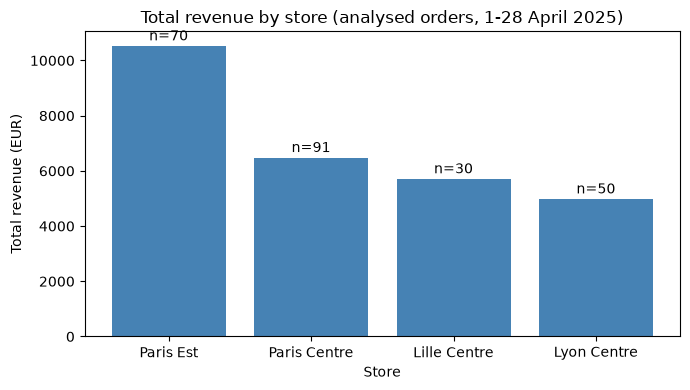

In [26]:
# Figure 1 — Total revenue by store

store_summary_sorted = store_summary.sort_values("total_revenue_eur", ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(store_summary_sorted["store_name"], store_summary_sorted["total_revenue_eur"], color="steelblue")
ax.set_title("Total revenue by store (analysed orders, 1-28 April 2025)")
ax.set_xlabel("Store")
ax.set_ylabel("Total revenue (EUR)")

for i, row in store_summary_sorted.iterrows():
    ax.text(row["store_name"], row["total_revenue_eur"] + 200,
            "n=" + str(row["order_count"]), ha="center")

plt.tight_layout()
fig.savefig(OUT_DIR / "figure1_total_revenue_by_store.png", dpi=150)
plt.show()

**Your interpretation**

State the question, unit and aggregation; then interpret the chart.

Question:
Which store generates the most total revenue? 

Unit: 
One store

Aggregation: 
Sum of revenue_eur by store.

Interpretation: 
Paris Est leads clearly (10,528.9 EUR), ahead of Paris Centre (6,482.9 EUR), Lille Centre (5,712.5 EUR) and Lyon Centre (4,982.5 EUR). The order counts (n) written above each bar show that Paris Centre has the most orders (n=91) yet a lower total than Paris Est (n=70): volume and total revenue do not move together here.

Limitation:
A high total can simply reflect more orders, not a higher-value basket; it says nothing about per-order performance, which Figure 2 addresses.

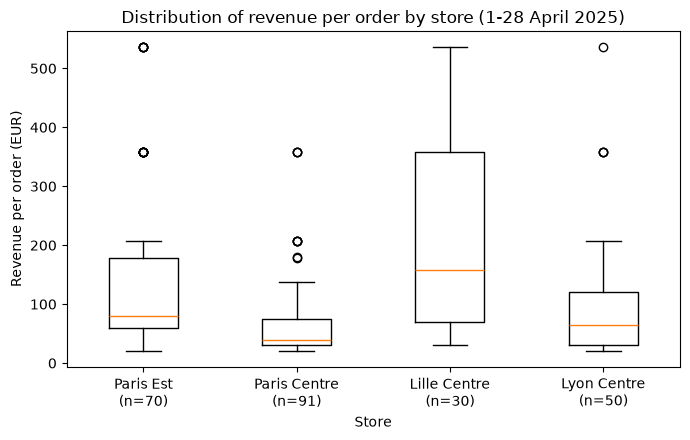

In [27]:
# Figure 2 — Distribution of order revenue

store_order = store_summary.sort_values("total_revenue_eur", ascending=False)["store_name"].tolist()

data_by_store = []
labels = []
for store in store_order:
    values = analysis.loc[analysis["store_name"] == store, "revenue_eur"]
    data_by_store.append(values)
    labels.append(store + "\n(n=" + str(len(values)) + ")")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(data_by_store)
ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels)
ax.set_title("Distribution of revenue per order by store (1-28 April 2025)")
ax.set_xlabel("Store")
ax.set_ylabel("Revenue per order (EUR)")
plt.tight_layout()
fig.savefig(OUT_DIR / "figure2_boxplot_revenue_by_store.png", dpi=150)
plt.show()

**Your interpretation**

State the question and observation unit; describe spread and a limitation.

Question: 
How does revenue per order distribute within each store (centre, spread, outliers)? 

Unit:
One order.

Interpretation:
Lille Centre’s median order value (158.5 EUR) stands well above Paris Centre’s (39.9 EUR), consistent with Lille’s product mix (78% Screens, vs 17% for Paris Centre). A few high-value orders appear as isolated points above the whiskers in several stores; they are legitimate sales of expensive products and should not be removed without evidence of error.

Limitation:
Group sizes are unequal (30 to 91 orders), so the smaller boxes (Lille Centre, Lyon Centre) are statistically less stable than the larger ones.

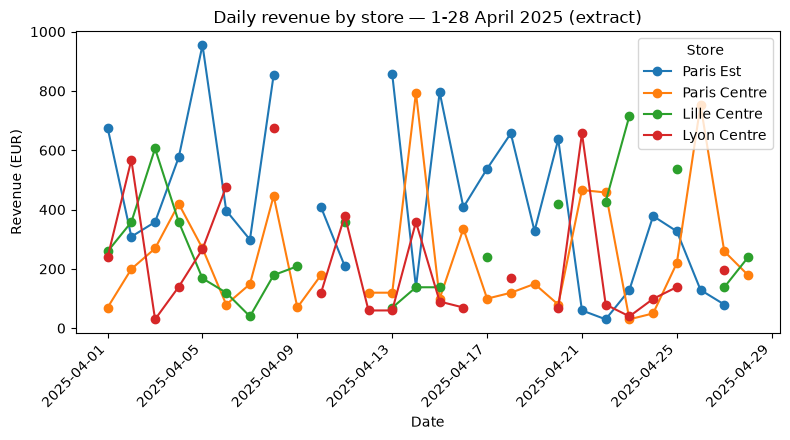

In [28]:
# Figure 3 — Daily sampled revenue

days = pd.date_range("2025-04-01", "2025-04-28", freq="D")

fig, ax = plt.subplots(figsize=(8, 4.5))
for store in store_order:
    daily_values = (analysis.loc[analysis["store_name"] == store]
                     .groupby("date")["revenue_eur"].sum()
                     .reindex(days))
    ax.plot(daily_values.index, daily_values.values, marker="o", label=store)

ax.set_title("Daily revenue by store — 1-28 April 2025 (extract)")
ax.set_xlabel("Date")
ax.set_ylabel("Revenue (EUR)")
ax.legend(title="Store")
fig.autofmt_xdate(rotation=45)
plt.tight_layout()
fig.savefig(OUT_DIR / "figure3_daily_revenue.png", dpi=150)
plt.show()

**Your interpretation**

What does one point represent? How did you treat missing dates?

One point represents one store-day: the summed revenue for a given store on a given date. Missing store-days are produced by .reindex(days), which inserts NaN for any date with no order in the extract. This breaks the line rather than drawing it down to zero, since a missing day is not evidence of zero sales.

Interpretation: 
Daily revenue is volatile for all four stores with no visible trend across the window; Paris Est and Paris Centre show more days with activity than Lille Centre, consistent with their higher order counts.

Limitation:
28 days is too short to detect a weekly or seasonal pattern, and gaps may reflect extract coverage rather than true store inactivity.


Figure 1 answers “how much in total,” Figure 2 answers “how is a typical order’s value distributed,” and Figure 3 answers “how does activity move over time.” None of the three alone would let us assess the manager’s claim correctly.

## 6. Write a decision brief
Write **six to eight sentences** addressed to the manager. Include:
- a clear answer to the original claim;
- at least two numerical results, with units and population;
- a distinction between total revenue and mean or median order revenue;
- a data-quality or integration limitation and a sample-coverage limitation;
- one plausible explanation labelled as a hypothesis;
- one proportionate next action and the extra data needed.

Avoid “Store X is best” without defining best. Do not claim causality, profitability or complete activity from this extract.

**Your interpretation**

Write your final decision brief here.

The manager's claim is only partially supported. Among the 241 orders retained for analysis (1-28 April 2025), Paris Est has the highest total revenue (10,528.9 EUR across 70 orders), but it is Lille Centre that has the highest median revenue per order (158.5 EUR), despite having the fewest orders (30). Total revenue and order-level revenue therefore answer different questions: a high total can come simply from a larger number of orders, as seen in Paris Centre, which has the most orders (91) yet ranks only second in total revenue because its median order (39.9 EUR) is small.

A data-quality limitation:
7 of 252 raw orders were excluded for invalid format (impossible date, non-numeric or negative quantity, missing or negative price), and 2 further orders were excluded for referencing an unknown store (S99) or product (P99), about 4% of raw rows excluded overall.

A coverage limitation:
This extract records only completed orders over 28 days and may not represent each store's full activity, so a store-day absent from Figure 3 is not evidence of zero sales. Hypothesis (not proven here): product mix plausibly explains much of the gap, since Screens make up 78% of Lille Centre's revenue and 66% of Paris Est's, against only 17% of Paris Centre's.
 
Proposed next action: 
Before replicating any store's "approach," compare category composition and, if available, costs and footfall across stores over a longer period, since revenue alone cannot establish profitability or causality.

## 7. Export and reproduce
Save `store_summary.csv`, `category_summary.csv`, `reconciliation.csv`, `sales_review.csv` and `integration_review.csv` into `case_study_outputs/`. Save the three figures as PNG files. Use `index=False` for tables.

Before submitting:
- restart the kernel and run all cells from top to bottom;
- check that joins did not multiply rows and revenue totals reconcile;
- check that raw files remain unchanged;
- remove abandoned trials and explain all final decisions;
- make sure every member can explain one cleaning decision, one join control and every chart.

The deliverable is the entire completed notebook, including interpretations, not just the first figure.

In [29]:
# Export the evidence

#7.1 Export the summary tables
tables = {'store_summary.csv': store_summary,
          'category_summary.csv': category_summary,
          'reconciliation.csv': reconciliation,
          'sales_review.csv': sales_review,
          'integration_review.csv': integration_review}
for file_name, table in tables.items():
    table.to_csv(OUT_DIR / file_name, index=False)
    print("Saved : ", OUT_DIR / file_name, table.shape)

#7.2 Check that the three figures were saved (Section 5)
for file_name in ['figure1_total_revenue_by_store.png',
                  'figure2_boxplot_revenue_by_store.png',
                  'figure3_daily_revenue.png']:
    assert (OUT_DIR / file_name).exists(), file_name
    print("Figure found : ", OUT_DIR / file_name)

#7.3 Final reproducibility checks

# Joins did not multiply rows and totals reconcile
assert len(step1) == len(step2) == len(sales_valid)
assert len(sales_raw) == n_dup + len(sales_review) + len(integration_review) + len(analysis)
assert np.isclose(store_summary['total_revenue_eur'].sum(), analysis['revenue_eur'].sum())

# Raw files and raw objects remain unchanged
assert pd.read_csv(DATA_DIR / 'case_sales.csv', dtype='string').equals(sales_raw)
assert pd.read_csv(DATA_DIR / 'case_stores.csv', dtype='string').equals(stores_raw)
assert pd.read_csv(DATA_DIR / 'case_products.csv', dtype='string').equals(products_raw)
print("All checks passed : joins, reconciliation and raw data unchanged")

Saved :  case_study_outputs\store_summary.csv (4, 7)
Saved :  case_study_outputs\category_summary.csv (4, 5)
Saved :  case_study_outputs\reconciliation.csv (8, 2)
Saved :  case_study_outputs\sales_review.csv (7, 13)
Saved :  case_study_outputs\integration_review.csv (2, 20)
Figure found :  case_study_outputs\figure1_total_revenue_by_store.png
Figure found :  case_study_outputs\figure2_boxplot_revenue_by_store.png
Figure found :  case_study_outputs\figure3_daily_revenue.png
All checks passed : joins, reconciliation and raw data unchanged


### OPTIONAL / IF TIME ALLOWS — Investigate product mix
Create a store × category table of revenue or order counts. Use a labelled heatmap or compare category shares within each store. State the denominator explicitly. Does the mix help explain different order amounts? Treat this as descriptive evidence, not a causal proof.

category,Accessories,Audio,Screens,Video
store_name,,,,
Paris Est,11.8,11.4,66.3,10.5
Paris Centre,49.6,15.7,16.6,18.1
Lille Centre,7.3,1.0,78.3,13.3
Lyon Centre,31.0,15.6,39.5,13.8


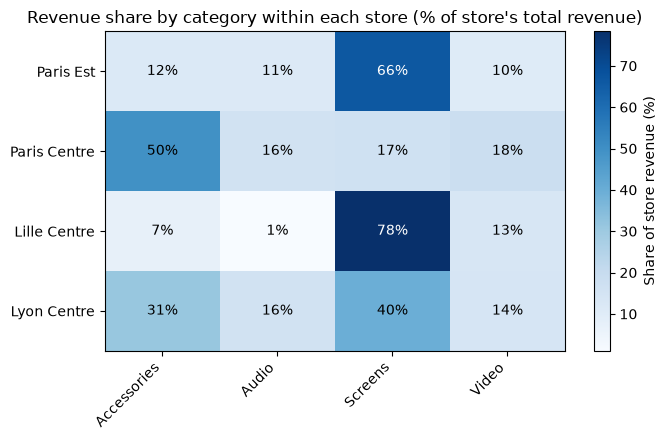

In [30]:
#8. Optional : store × category 
store_category_revenue = (analysis.groupby(['store_name', 'category'])['revenue_eur']
                           .sum()
                           .unstack(fill_value=0))

store_category_share = store_category_revenue.div(store_category_revenue.sum(axis=1), axis=0) * 100
store_category_share = store_category_share.loc[store_order]

display(store_category_share.round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
heatmap_data = store_category_share.to_numpy(dtype=float)
im = ax.imshow(heatmap_data, cmap='Blues', aspect='auto')

ax.set_xticks(range(len(store_category_share.columns)))
ax.set_xticklabels(store_category_share.columns, rotation=45, ha='right')
ax.set_yticks(range(len(store_category_share.index)))
ax.set_yticklabels(store_category_share.index)
ax.set_title("Revenue share by category within each store (% of store's total revenue)")

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        ax.text(j, i, f"{heatmap_data[i, j]:.0f}%", ha='center', va='center',
                color='white' if heatmap_data[i, j] > 50 else 'black')

fig.colorbar(im, ax=ax, label='Share of store revenue (%)')
plt.tight_layout()
fig.savefig(OUT_DIR / "figure4_optional_store_category_mix.png", dpi=150)
plt.show()

The denominator is each store’s total revenue (each row sums to 100%). Product mix helps explain the differences observed: Lille Centre (78%) and Paris Est (66%) are dominated by Screens, which pulls their mean revenue per order upward, whereas Paris Centre draws most of its revenue from Accessories (50%), a lower unit-price category, consistent with its notably lower median order value. Lyon Centre shows an intermediate profile (40% Screens, 31% Accessories). This remains descriptive evidence: category composition correlates with the differences in mean order revenue, but does not prove causality (other factors : foot traffic, store size ; remain unknown).